# 02 Binary Classification: Normal vs Attack

**Project:** Network Intrusion Detection Using Machine Learning  
**Task:** Binary Classification (Normal = 0, Attack = 1)  

This notebook trains and benchmarks seven machine learning algorithms:
1. **Logistic Regression** (baseline, balanced class weights)
2. **Decision Tree** (CART with balanced class weights)
3. **Random Forest** (ensemble with balanced class weights)
4. **K-Nearest Neighbors (KNN)** (instance-based classification)
5. **Naive Bayes** (GaussianNB)
6. **XGBoost** (gradient boosted decision trees)
7. **Support Vector Machine** (SVM on a representative stratified sample)

### Pipeline Steps:
- Stratified 5-fold cross-validation on training data (107,740 records)
- Hyperparameter tuning for top candidate algorithms using `RandomizedSearchCV`
- Independent evaluation on the held-out test set (55,945 records)
- Model selection based on Macro-F1 and Attack-class Recall (per `rules.md`)
- Serialization of `models/best_binary.joblib` and reporting artifacts to `reports/`

In [1]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import joblib

# Ensure project root is in sys.path
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import config, data_loader, preprocess, features, models, train, evaluate

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['figure.dpi'] = 100
print('Environment and modules loaded successfully.')

Environment and modules loaded successfully.


## 1. Load Processed Splits and Preprocessing Artifacts

In [2]:
train_df, test_df = data_loader.load_processed()
preprocessor = preprocess.load_preprocessor()
feature_cols = preprocess.load_feature_columns()
selected_features = features.load_selected_features()
all_feature_names = preprocessor.get_feature_names_out().tolist()

# Transform features and apply feature selection
X_train_full = preprocess.transform_features(preprocessor, train_df[feature_cols])
X_train_sel = features.filter_features(X_train_full, all_feature_names, selected_features)
y_train = train_df[config.BINARY_TARGET].values

X_test_full = preprocess.transform_features(preprocessor, test_df[feature_cols])
X_test_sel = features.filter_features(X_test_full, all_feature_names, selected_features)
y_test = test_df[config.BINARY_TARGET].values

print(f'Training feature matrix: {X_train_sel.shape[0]:,} rows x {X_train_sel.shape[1]} selected features')
print(f'Testing feature matrix:  {X_test_sel.shape[0]:,} rows x {X_test_sel.shape[1]} selected features')
print(f'Class balance in train: Normal(0)={(y_train == 0).sum():,}, Attack(1)={(y_train == 1).sum():,}')

2026-10-29 01:24:05,746 [INFO] Loading cleaned datasets from Parquet: C:\Users\Ankit007\OneDrive\Documents\final year project\data\processed\train_cleaned.parquet, C:\Users\Ankit007\OneDrive\Documents\final year project\data\processed\test_cleaned.parquet


Training feature matrix: 107,740 rows x 30 selected features
Testing feature matrix:  55,945 rows x 30 selected features
Class balance in train: Normal(0)=51,890, Attack(1)=55,850


## 2. Stratified 5-Fold Cross-Validation on Candidate Models

We evaluate all seven models using Stratified 5-fold CV to ensure balanced class representation across all validation folds without test-set leakage.

2026-10-29 01:24:06,337 [INFO] Starting stratified 5-fold cross-validation across all candidate models (107740 samples, 30 features)


2026-10-29 01:24:06,338 [INFO] Evaluating 5-fold cross-validation for: Logistic Regression


2026-10-29 01:24:10,809 [INFO] Logistic Regression -> Acc: 0.8975 | Prec: 0.8451 | Recall: 0.9824 | Macro-F1: 0.8960 | ROC-AUC: 0.9565


2026-10-29 01:24:10,811 [INFO] Evaluating 5-fold cross-validation for: Decision Tree


2026-10-29 01:24:16,647 [INFO] Decision Tree -> Acc: 0.9228 | Prec: 0.9222 | Recall: 0.9296 | Macro-F1: 0.9227 | ROC-AUC: 0.9684


...

2026-10-29 01:24:58,733 [INFO] Evaluating 5-fold cross-validation for: XGBoost


2026-10-29 01:25:02,272 [INFO] XGBoost -> Acc: 0.9295 | Prec: 0.9124 | Recall: 0.9557 | Macro-F1: 0.9292 | ROC-AUC: 0.9847


2026-10-29 01:25:02,273 [INFO] Evaluating 5-fold cross-validation for: SVM (Sampled)


2026-10-29 01:25:04,357 [INFO] SVM (Sampled) -> Acc: 0.8969 | Prec: 0.8448 | Recall: 0.9816 | Macro-F1: 0.8954 | ROC-AUC: 0.9557



--- 5-Fold Stratified Cross-Validation Benchmark Results ---
              model  accuracy  precision  recall  f1_macro  roc_auc
      Random Forest    0.9307     0.9129  0.9577    0.9304   0.9854
            XGBoost    0.9295     0.9124  0.9557    0.9292   0.9847
      Decision Tree    0.9228     0.9222  0.9296    0.9227   0.9684
                KNN    0.9088     0.9007  0.9262    0.9086   0.9666
Logistic Regression    0.8975     0.8451  0.9824    0.8960   0.9565
      SVM (Sampled)    0.8969     0.8448  0.9816    0.8954   0.9557
        Naive Bayes    0.6334     0.8326  0.3665    0.6082   0.8670


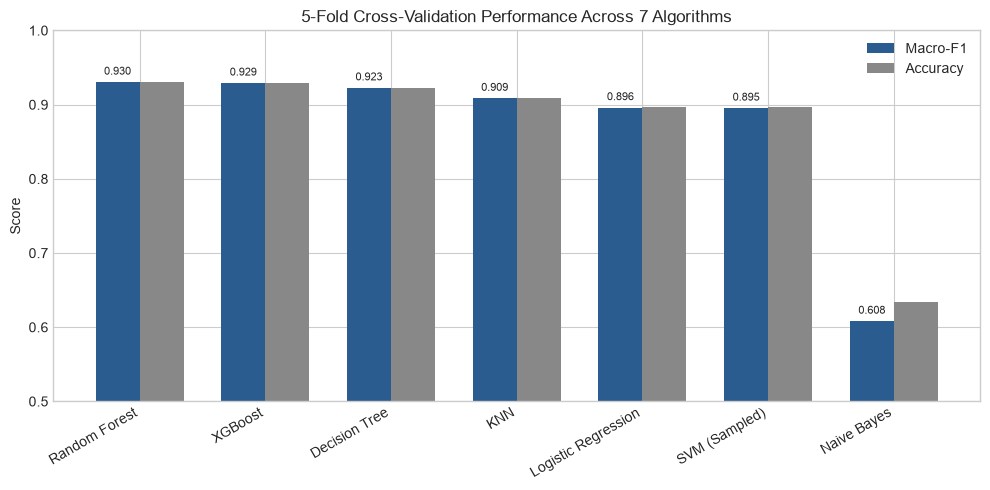

In [3]:
df_cv = train.evaluate_cv_binary_models(X_train_sel, y_train, cv_splits=5)
print('\n--- 5-Fold Stratified Cross-Validation Benchmark Results ---')
print(df_cv.to_string(index=False))

# Plot Cross-Validation F1-Macro and Accuracy
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_cv))
width = 0.35

ax.bar(x - width/2, df_cv['f1_macro'], width, label='Macro-F1', color='#2b5c8f')
ax.bar(x + width/2, df_cv['accuracy'], width, label='Accuracy', color='#888888')

ax.set_ylabel('Score')
ax.set_title('5-Fold Cross-Validation Performance Across 7 Algorithms')
ax.set_xticks(x)
ax.set_xticklabels(df_cv['model'], rotation=30, ha='right')
ax.set_ylim([0.5, 1.0])
ax.legend()

for i, v in enumerate(df_cv['f1_macro']):
    ax.text(i - width/2, v + 0.01, f'{v:.3f}', ha='center', fontsize=8)

plt.tight_layout()
plt.show()

## 3. Hyperparameter Tuning of Leading Models

We tune the top candidate algorithms (Random Forest, XGBoost, Decision Tree) on the training folds using cross-validated randomized search optimizing for Macro-F1.

In [4]:
top_models_to_tune = ['Random Forest', 'XGBoost', 'Decision Tree']
tuned_models = {}

for name in top_models_to_tune:
    best_clf, best_params, best_score = train.tune_binary_model(name, X_train_sel, y_train, n_iter=6, cv_splits=3)
    tuned_models[f'{name} (Tuned)'] = best_clf
    print(f'{name} (Tuned) Best CV Macro-F1: {best_score:.4f}')
    print(f'Parameters: {best_params}\n')

2026-10-29 01:25:04,684 [INFO] Tuning hyperparameters for Random Forest using RandomizedSearchCV (n_iter=6)


2026-10-29 01:25:55,567 [INFO] Tuned Random Forest successfully. Best Macro-F1: 0.9316 | Best Params: {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 20}


2026-10-29 01:25:55,569 [INFO] Tuning hyperparameters for XGBoost using RandomizedSearchCV (n_iter=6)


Random Forest (Tuned) Best CV Macro-F1: 0.9316
Parameters: {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 20}



2026-10-29 01:26:05,796 [INFO] Tuned XGBoost successfully. Best Macro-F1: 0.9298 | Best Params: {'subsample': 1.0, 'n_estimators': 150, 'max_depth': 6, 'learning_rate': 0.08, 'colsample_bytree': 1.0}


2026-10-29 01:26:05,797 [INFO] Tuning hyperparameters for Decision Tree using RandomizedSearchCV (n_iter=6)


XGBoost (Tuned) Best CV Macro-F1: 0.9298
Parameters: {'subsample': 1.0, 'n_estimators': 150, 'max_depth': 6, 'learning_rate': 0.08, 'colsample_bytree': 1.0}



2026-10-29 01:26:11,922 [INFO] Tuned Decision Tree successfully. Best Macro-F1: 0.9200 | Best Params: {'min_samples_split': 2, 'min_samples_leaf': 5, 'max_depth': 16, 'criterion': 'entropy'}


Decision Tree (Tuned) Best CV Macro-F1: 0.9200
Parameters: {'min_samples_split': 2, 'min_samples_leaf': 5, 'max_depth': 16, 'criterion': 'entropy'}



## 4. Independent Evaluation on Held-Out Test Set (55,945 Records)

We evaluate baseline models and tuned variants on the held-out test split, reporting Accuracy, Precision, Recall, Macro-F1, Weighted-F1, and ROC-AUC.

In [5]:
test_results = []
all_candidate_clfs = models.get_models('binary')

# Fit baseline models on full training set and evaluate on test set
fitted_estimators = {}
for name, clf in all_candidate_clfs.items():
    clf.fit(X_train_sel, y_train)
    fitted_estimators[name] = clf
    
    y_pred = clf.predict(X_test_sel)
    y_prob = clf.predict_proba(X_test_sel) if hasattr(clf, 'predict_proba') else None
    metrics = evaluate.compute_binary_metrics(y_test, y_pred, y_prob)
    metrics['model'] = name
    test_results.append(metrics)

# Evaluate tuned models
for name, tuned_clf in tuned_models.items():
    y_pred = tuned_clf.predict(X_test_sel)
    y_prob = tuned_clf.predict_proba(X_test_sel) if hasattr(tuned_clf, 'predict_proba') else None
    metrics = evaluate.compute_binary_metrics(y_test, y_pred, y_prob)
    metrics['model'] = name
    test_results.append(metrics)
    fitted_estimators[name] = tuned_clf

# Save comparison table to reports/binary_comparison.csv
df_comparison = evaluate.save_comparison_table(test_results, config.BINARY_COMPARISON_PATH)
print('--- Test Set Evaluation Benchmark Table ---')
print(df_comparison.to_string(index=False))

2026-10-29 01:26:40,490 [INFO] Saved comparison table (10 models) to: C:\Users\Ankit007\OneDrive\Documents\final year project\reports\binary_comparison.csv


--- Test Set Evaluation Benchmark Table ---
 accuracy  precision  recall  f1_attack  f1_macro  f1_weighted  roc_auc                 model
   0.8379     0.7282  0.9299     0.8168    0.8357       0.8399   0.9207         Decision Tree
   0.8347     0.7202  0.9397     0.8155    0.8329       0.8368   0.9367 Decision Tree (Tuned)
   0.8315     0.7045  0.9754     0.8181    0.8306       0.8334   0.9676 Random Forest (Tuned)
   0.8295     0.7019  0.9752     0.8163    0.8286       0.8313   0.9719       XGBoost (Tuned)
   0.8280     0.6991  0.9784     0.8155    0.8272       0.8298   0.9726               XGBoost
   0.8269     0.6978  0.9779     0.8145    0.8261       0.8287   0.9695         Random Forest
   0.7964     0.6755  0.9158     0.7775    0.7949       0.7988   0.9020                   KNN
   0.7403     0.6047  0.9580     0.7414    0.7403       0.7401   0.8883         SVM (Sampled)
   0.7396     0.6033  0.9637     0.7420    0.7396       0.7391   0.8882   Logistic Regression
   0.6605     0.

## 5. Model Selection, Pipeline Packaging, and Persistence

We select the winning binary model based on Macro-F1 and Attack-class recall. The model is packaged into an end-to-end `Pipeline` containing `FeatureSelector` and saved to `models/best_binary.joblib`.

In [6]:
best_row = df_comparison.iloc[0]
best_name = str(best_row['model'])
best_estimator = fitted_estimators[best_name]
print(f'Selected Best Model: {best_name}')
print(f'Test Accuracy:     {best_row["accuracy"]:.4f}')
print(f'Test Macro-F1:     {best_row["f1_macro"]:.4f}')
print(f'Test Attack Recall:{best_row["recall"]:.4f}')
print(f'Test ROC-AUC:      {best_row["roc_auc"]:.4f}')

# Create pipeline with FeatureSelector
from sklearn.pipeline import Pipeline
best_pipeline = Pipeline([
    ('selector', features.FeatureSelector(selected_features=selected_features, all_feature_names=all_feature_names)),
    ('classifier', best_estimator)
])

# Save pipeline
joblib.dump(best_pipeline, config.BEST_BINARY_MODEL_PATH)
print(f'\nSuccessfully saved best binary model to: {config.BEST_BINARY_MODEL_PATH}')

# Generate Confusion Matrix and ROC curve
test_preds = best_pipeline.predict(X_test_full)
test_probs = best_pipeline.predict_proba(X_test_full) if hasattr(best_pipeline, 'predict_proba') else None

evaluate.plot_binary_confusion_matrix(y_test, test_preds, best_name, config.FIGURES_DIR / 'cm_binary_best.png')
if test_probs is not None:
    evaluate.plot_binary_roc_curve(y_test, test_probs, best_name, config.FIGURES_DIR / 'roc_binary_best.png')

# Verify pipeline on data/sample/sample_input.csv
sample_df = pd.read_csv(config.SAMPLE_INPUT_PATH)
X_sample_trans = preprocess.transform_features(preprocessor, sample_df)
sample_preds = best_pipeline.predict(X_sample_trans)
print(f'Sample Input Verification: successfully predicted {len(sample_preds)} rows.')
print(f'Sample Predictions Count: Normal(0)={(sample_preds == 0).sum()}, Attack(1)={(sample_preds == 1).sum()}')

Selected Best Model: Decision Tree
Test Accuracy:     0.8379
Test Macro-F1:     0.8357
Test Attack Recall:0.9299
Test ROC-AUC:      0.9207

Successfully saved best binary model to: C:\Users\Ankit007\OneDrive\Documents\final year project\models\best_binary.joblib


2026-10-29 01:26:41,016 [INFO] Saved confusion matrix plot to: C:\Users\Ankit007\OneDrive\Documents\final year project\reports\figures\cm_binary_best.png


2026-10-29 01:26:41,333 [INFO] Saved ROC curve plot to: C:\Users\Ankit007\OneDrive\Documents\final year project\reports\figures\roc_binary_best.png


Sample Input Verification: successfully predicted 200 rows.
Sample Predictions Count: Normal(0)=98, Attack(1)=102
